<a href="https://colab.research.google.com/github/sophiannunez18/DSC_110/blob/main/ML_Evaluation_Explainability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# This was used to import our dataset as pd, the other codes used were to help us organize our data to then be able to build other models

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
# This code was used to load out training/testing datasets to use them for our model

X_train = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/X_train.csv')
X_test = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/X_test.csv')
y_train = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/y_train.csv')
y_test = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/y_test.csv')

#to prevent warning, converting the y from df to 1d series
y_train = y_train.squeeze()
y_test  = y_test.squeeze()

In [ ]:
# This shows us the first 5 rows of our dataset
X_train.head()

,age,bmi,height_cm,systolic_bp,gender_Male,race_ethnicity_Black,race_ethnicity_Mexican American,race_ethnicity_Other,race_ethnicity_Other Hispanic,race_ethnicity_White,education_College grad,education_Do not know,education_High school,education_Less than 9th,education_Some college
0,0.321165,0.183891,-1.310308,0.446166,False,False,False,False,False,True,False,False,True,False,False
1,0.776425,-1.080948,-0.062021,-0.739931,False,False,False,False,False,True,False,False,True,False,False
2,0.548795,1.885958,1.061437,0.633444,False,True,False,False,False,False,True,False,False,False,False
3,1.459315,-0.009844,0.000959,-0.018182,False,False,False,False,False,True,False,False,False,True,False
4,-0.987708,-0.987256,0.494034,-0.178096,True,False,False,False,True,False,False,False,False,True,False


In [ ]:
# Build the Random Forest model

rf = RandomForestClassifier(random_state = 42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

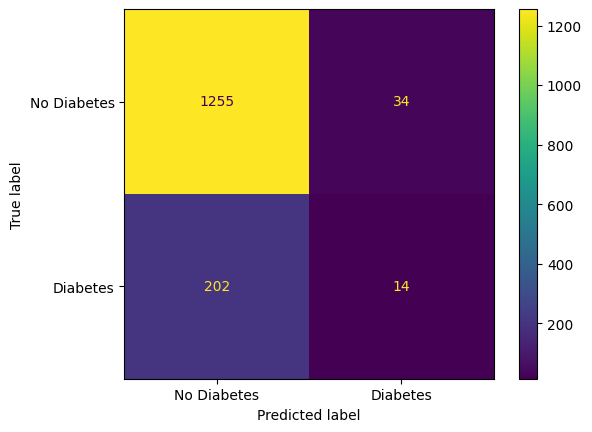

In [ ]:
# Evaluate this model using the different evaluation metrics
y_pred = rf.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
                                        display_labels = ['No Diabetes','Diabetes'])
plt.show()

In [ ]:
# This code was used to evaluate how weel our model is predicting

from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.97      0.91      1289
           1       0.29      0.06      0.11       216

    accuracy                           0.84      1505
   macro avg       0.58      0.52      0.51      1505
weighted avg       0.78      0.84      0.80      1505



In [ ]:
# This was used to calculate the AUC, which is the area under the curve for our random forest model we created
from sklearn.metrics import roc_auc_score
y_prob = rf.predict_proba(X_test)[:, 1]
print(f"AUC for Random Forest is {roc_auc_score(y_test, y_prob):.2f}")

AUC for Random Forest is 0.75


In [ ]:
# Play woth the threshold and generate the evluation metrics
# Change the threshold to 0.3
y_pred_03 = (y_prob >= 0.3).astype(int)
print(classification_report(y_test, y_pred_03))

              precision    recall  f1-score   support

           0       0.89      0.87      0.88      1289
           1       0.34      0.39      0.36       216

    accuracy                           0.80      1505
   macro avg       0.62      0.63      0.62      1505
weighted avg       0.81      0.80      0.81      1505



In [ ]:
# Change the threshold for positive to be 0.7 and watch what happens to the specificity
y_pred_07 = (y_prob >= 0.7).astype(int)
print(classification_report(y_test, y_pred_07))

              precision    recall  f1-score   support

           0       0.86      0.99      0.92      1289
           1       0.11      0.00      0.01       216

    accuracy                           0.85      1505
   macro avg       0.48      0.50      0.46      1505
weighted avg       0.75      0.85      0.79      1505



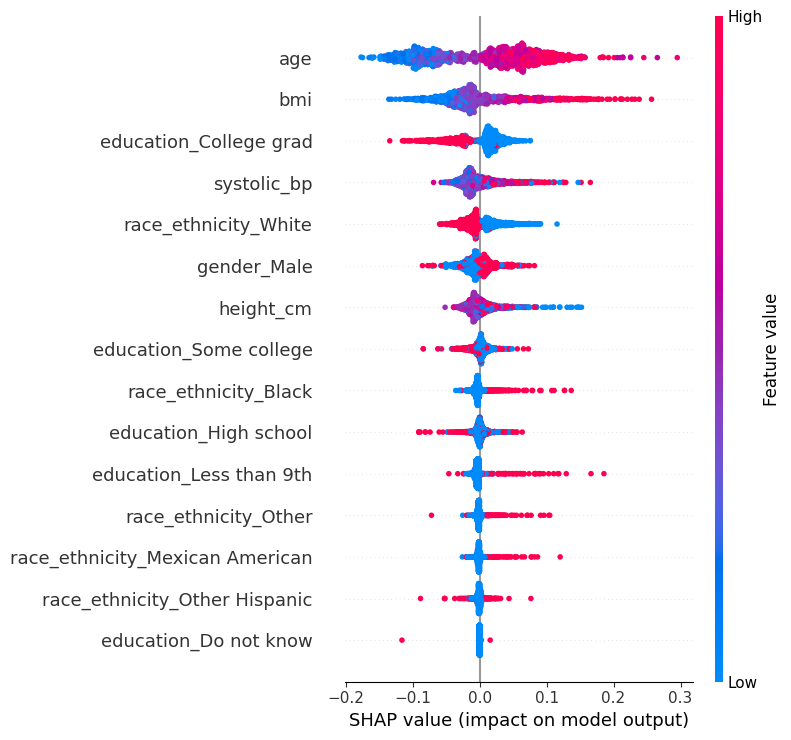

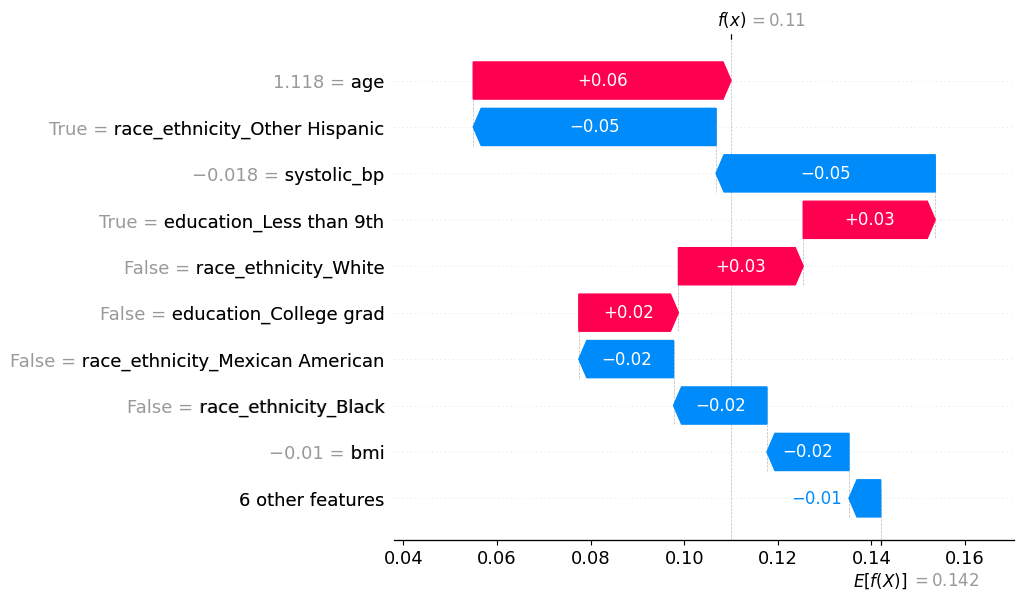

In [ ]:
# This was used to import a library that is called shap

import shap

explainer = shap.TreeExplainer(rf)
shap_values = explainer(X_test)          # newer API — returns Explanation object

# overall summary plot
shap.summary_plot(shap_values[:, :, 1], X_test)   # [:, :, 1] = all rows, all features, positive class

# single observation (row 0)
shap.plots.waterfall(shap_values[0, :, 1])         # cleaner than force_plot for single obs

In [ ]:
# This was used to install the h20 library into our code
pip install h2o

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 266.3/266.3 MB 27.9 MB/s  0:00:09
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for h2o: filename=h2o-3.46.0.12-py2.py3-none-any.whl size=266411235 sha256=8b21b7a1c0ae34523b50780f803a52f86436d70294b56f43e6596de58b3d4398
  Stored in directory: /root/.cache/pip/wheels/2d/d1/1c/742fac210b3d4c1578163533b3f96a51659aac2702838347af
Successfully built h2o


In [ ]:
# The following lines of code were used to build, train, and test different models to find and display our predictions based on our dataset

import h2o
from h2o.automl import H2OAutoML

h2o.init()

# convert your existing splits
train = h2o.H2OFrame(X_train.assign(target=y_train))
test  = h2o.H2OFrame(X_test.assign(target=y_test))

x = X_train.columns.tolist()
y = 'target'

train['target'] = train['target'].asfactor()
test['target']  = test['target'].asfactor()

aml = H2OAutoML(max_models=10, seed=42)
aml.train(x=x, y=y, training_frame=train)

# leaderboard
aml.leaderboard.head()

# best model predictions
preds = aml.leader.predict(test)

Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
  Java Version: [0.021s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate; [0.021s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate; openjdk version "21.0.12.1" 2026-08-18; OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu); OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
  Starting server from /usr/local/lib/python3.13/dist-packages/h2o/backend/bin/h2o.jar
  Ice root: /tmp/tmpwqqcrag8
  JVM stdout: /tmp/tmpwqqcrag8/h2o_unknownUser_started_from_python.out
  JVM stderr: /tmp/tmpwqqcrag8/h2o_unknownUser_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server a

H2O_cluster_uptime:,08 secs
H2O_cluster_timezone:,Etc/UTC
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.12
H2O_cluster_version_age:,2 months and 30 days
H2O_cluster_name:,H2O_from_python_unknownUser_ubn2jr
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,3.149 Gb
H2O_cluster_total_cores:,2
H2O_cluster_allowed_cores:,2
H2O_cluster_status:,"locked, healthy"



+------------------------------------------------------------------+
| You are running the community edition of H2O-3 OSS.              |
|                                                                  |
| For commercial use, H2O-3 Secure is now recommended.             |
| This includes production support, CVE fixes, multi-node scaling, |
| model artifact extraction, and more.                             |
| See h2o.ai/h2o-3/oss-vs-secure for additional details.           |
| Contact enterprise@h2o.ai to upgrade.                            |
+------------------------------------------------------------------+
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%
stackedensemble prediction progress: |███████████████████████████████████████████| (done) 100

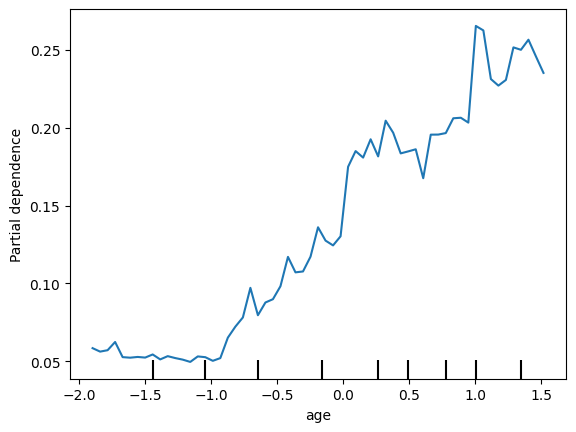

In [ ]:
# This code was used to import tools that help us change variables in our prediction model, we are now able to visualize this information

from sklearn.inspection import PartialDependenceDisplay

# replace 'age' with any feature name (or column index)
PartialDependenceDisplay.from_estimator(
    rf,
    X_test,
    features=['age']          # list of features to plot
)

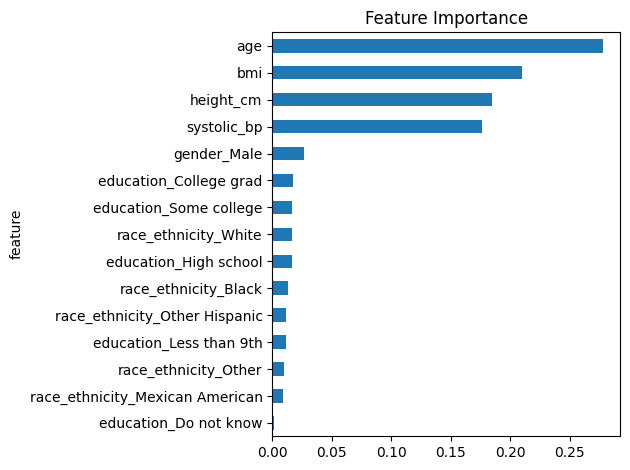

In [ ]:
# This code was used to make a feature importance graphs that shows us our variables in our random forest model that was used to make predictions

importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=True)

importance_df.plot(
    kind='barh',
    x='feature', y='importance',
    legend=False, title='Feature Importance'
)
plt.tight_layout()
plt.show()